In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
# Data handling
import pandas as pd
import numpy as np

# Preprocessing & evaluation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

# Machine Learning
from xgboost import XGBClassifier

# Deep Learning
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Reproducibility
import random


In [ ]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/DatasetBigData/combined_dataset.csv")
print("Initial shape:", df.shape)
df.head()


Initial shape: (95910, 12)


,domain,ranking,isIp,valid,activeDuration,urlLen,is@,isredirect,haveDash,domainLen,nosOfSubdomain,label
0,www.voting-yahoo.com,10000000,0,0,0,20,0,0,1,20,2,1
1,www.zvon.org/xxl/WSDL1.1/Output/index.html,194914,0,1,7305,42,0,0,0,12,2,0
2,tecportais.com/file-security-update-infonfmati...,10000000,0,0,0,155,0,0,0,14,1,1
3,bima.astro.umd.edu/nemo/linuxastro/,7001,0,0,0,35,0,0,0,18,3,0
4,huarui-tec.com/js/?us.battle.net/login/en/?ref...,10000000,0,1,730,79,0,0,1,14,1,1


Pre-Processing

In [ ]:
df = df.drop_duplicates()


In [ ]:
categorical_cols = df.select_dtypes(include=['object']).columns
print("Dropped string columns:", categorical_cols)

df = df.drop(columns=categorical_cols)


Dropped string columns: Index(['domain'], dtype='object')


In [ ]:
df = df.drop(columns=['valid'])


In [ ]:
df = df.fillna(df.median())


In [ ]:
X = df.drop(columns=['label'])   # fitur URL
y = df['label']                  # target phishing


In [ ]:
print(y.value_counts())


label
1    41338
0    31025
Name: count, dtype: int64


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=seed,
    stratify=y
)


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)


XGboost

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['label'])
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)


In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train_scaled, y_train)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
xgb_pred = xgb_model.predict(X_test_scaled)
xgb_prob = xgb_model.predict_proba(X_test_scaled)[:, 1]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    mean_squared_error
)

accuracy  = accuracy_score(y_test, xgb_pred)
precision = precision_score(y_test, xgb_pred)
recall    = recall_score(y_test, xgb_pred)
f1        = f1_score(y_test, xgb_pred)
auc       = roc_auc_score(y_test, xgb_prob)
mse       = mean_squared_error(y_test, xgb_pred)

print("=== XGBoost Performance ===")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"AUC-ROC   : {auc:.4f}")
print(f"MSE       : {mse:.4f}")


=== XGBoost Performance ===
Accuracy  : 0.9478
Precision : 0.9499
Recall    : 0.9611
F1-score  : 0.9555
AUC-ROC   : 0.9894
MSE       : 0.0522


Transformer

In [ ]:
train_dataset = TensorDataset(
    torch.tensor(X_train_scaled, dtype=torch.float32),
    torch.tensor(y_train.values, dtype=torch.long)
)

test_dataset = TensorDataset(
    torch.tensor(X_test_scaled, dtype=torch.float32),
    torch.tensor(y_test.values, dtype=torch.long)
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=64, shuffle=False)


In [ ]:
class TabularTransformer(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.embedding = nn.Linear(input_dim, 64)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.classifier = nn.Linear(64, 2)

    def forward(self, x):
        x = self.embedding(x).unsqueeze(1)
        x = self.transformer(x).squeeze(1)
        return self.classifier(x)


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = TabularTransformer(X_train_scaled.shape[1]).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 100

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)

        optimizer.zero_grad()
        outputs = model(xb)
        loss = criterion(outputs, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs}] | Loss: {total_loss/len(train_loader):.4f}")


Epoch [1/100] | Loss: 0.2466
Epoch [2/100] | Loss: 0.2183
Epoch [3/100] | Loss: 0.2100
Epoch [4/100] | Loss: 0.2043
Epoch [5/100] | Loss: 0.2005
Epoch [6/100] | Loss: 0.1974
Epoch [7/100] | Loss: 0.1960
Epoch [8/100] | Loss: 0.1916
Epoch [9/100] | Loss: 0.1918
Epoch [10/100] | Loss: 0.1885
Epoch [11/100] | Loss: 0.1888
Epoch [12/100] | Loss: 0.1882
Epoch [13/100] | Loss: 0.1879
Epoch [14/100] | Loss: 0.1857
Epoch [15/100] | Loss: 0.1846
Epoch [16/100] | Loss: 0.1834
Epoch [17/100] | Loss: 0.1827
Epoch [18/100] | Loss: 0.1813
Epoch [19/100] | Loss: 0.1814
Epoch [20/100] | Loss: 0.1805
Epoch [21/100] | Loss: 0.1807
Epoch [22/100] | Loss: 0.1799
Epoch [23/100] | Loss: 0.1790
Epoch [24/100] | Loss: 0.1790
Epoch [25/100] | Loss: 0.1788
Epoch [26/100] | Loss: 0.1777
Epoch [27/100] | Loss: 0.1766
Epoch [28/100] | Loss: 0.1761
Epoch [29/100] | Loss: 0.1767
Epoch [30/100] | Loss: 0.1768
Epoch [31/100] | Loss: 0.1760
Epoch [32/100] | Loss: 0.1747
Epoch [33/100] | Loss: 0.1744
Epoch [34/100] | Lo

In [ ]:
model.eval()
preds, targets = [], []

with torch.no_grad():
    for xb, yb in test_loader:
        xb, yb = xb.to(device), yb.to(device)
        outputs = model(xb)
        preds.extend(outputs.argmax(1).cpu().numpy())
        targets.extend(yb.cpu().numpy())

print("Transformer Accuracy :", accuracy_score(targets, preds))
print("Transformer F1-score :", f1_score(targets, preds))


Transformer Accuracy : 0.9366406411939473
Transformer F1-score : 0.9448288309969316


Hybrid

In [ ]:
def extract_features(model, loader):
    model.eval()
    features, labels = [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            x = model.embedding(xb).unsqueeze(1)
            x = model.transformer(x).squeeze(1)
            features.append(x.cpu().numpy())
            labels.append(yb.numpy())

    return np.vstack(features), np.hstack(labels)

X_train_feat, y_train_feat = extract_features(model, train_loader)
X_test_feat, y_test_feat   = extract_features(model, test_loader)


In [ ]:
xgb_hybrid = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=seed,
    eval_metric="logloss"
)

xgb_hybrid.fit(X_train_feat, y_train_feat)

hybrid_pred = xgb_hybrid.predict(X_test_feat)

print("Hybrid Accuracy :", accuracy_score(y_test_feat, hybrid_pred))
print("Hybrid F1-score :", f1_score(y_test_feat, hybrid_pred))


Hybrid Accuracy : 0.9405099150141643
Hybrid F1-score : 0.9479412298204245


CATBoost

In [ ]:
!pip install catboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.4 MB/s eta 0:00:00


In [ ]:
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

# Split (PAKAI DATA YANG SAMA)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Model
cat_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function='Logloss',
    eval_metric='F1',
    verbose=False,
    random_seed=42
)

# Train
cat_model.fit(X_train, y_train)

# Predict
y_pred = cat_model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
f1  = f1_score(y_test, y_pred)

print("CatBoost Accuracy :", acc)
print("CatBoost F1-score :", f1)


CatBoost Accuracy : 0.9449319422372694
CatBoost F1-score : 0.9519908439250647


In [ ]:
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd


In [ ]:
def run_catboost_experiment(X_data, y_data, scenario_name):
    # Split (STRATIFIED)
    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_data,
        test_size=0.2,
        random_state=42,
        stratify=y_data
    )

    # Model
    model = CatBoostClassifier(
        iterations=500,
        depth=6,
        learning_rate=0.05,
        loss_function='Logloss',
        eval_metric='F1',
        random_seed=42,
        verbose=False
    )

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred)

    print(f"[CatBoost – {scenario_name}] Accuracy: {acc:.4f} | F1-score: {f1:.4f}")

    return {
        "Model": "CatBoost",
        "Feature_Set": scenario_name,
        "Accuracy": acc,
        "F1-score": f1
    }


In [ ]:
results_catboost = []

res_cb_topk = run_catboost_experiment(
    X_topk, y,
    scenario_name="Top-K Features"
)

results_catboost.append(res_cb_topk)


[CatBoost – Top-K Features] Accuracy: 0.9447 | F1-score: 0.9518


In [ ]:
res_cb_reduced = run_catboost_experiment(
    X_reduced, y,
    scenario_name="Reduced Features"
)

results_catboost.append(res_cb_reduced)


[CatBoost – Reduced Features] Accuracy: 0.9459 | F1-score: 0.9529


FEATURE IMPORTANCE

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Ambil feature importance
importance = xgb_model.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

feature_importance_df


,Feature,Importance
2,activeDuration,0.375632
3,urlLen,0.187627
0,ranking,0.140462
8,nosOfSubdomain,0.131763
7,domainLen,0.071118
5,isredirect,0.058991
6,haveDash,0.023139
4,is@,0.011267
1,isIp,0.000000


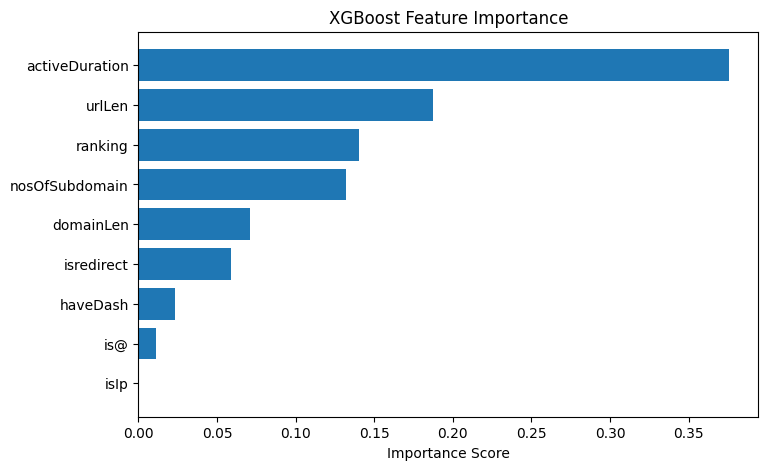

In [ ]:
plt.figure(figsize=(8, 5))
plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance"]
)
plt.gca().invert_yaxis()
plt.xlabel("Importance Score")
plt.title("XGBoost Feature Importance")
plt.show()


In [ ]:
K = 5

top_k_features = feature_importance_df.head(K)["Feature"].tolist()
print("Top-K Features:", top_k_features)


Top-K Features: ['activeDuration', 'urlLen', 'ranking', 'nosOfSubdomain', 'domainLen']


In [ ]:
N = 2

low_importance_features = feature_importance_df.tail(N)["Feature"].tolist()
print("Low-importance Features:", low_importance_features)


Low-importance Features: ['is@', 'isIp']


In [ ]:
reduced_features = [
    f for f in X.columns if f not in low_importance_features
]

print("Reduced Feature Set:", reduced_features)


Reduced Feature Set: ['ranking', 'activeDuration', 'urlLen', 'isredirect', 'haveDash', 'domainLen', 'nosOfSubdomain']


BUAT DATASET

In [ ]:
X_full = X.copy()


In [ ]:
X_topk = X[top_k_features]


In [ ]:
X_reduced = X[reduced_features]


Full Features    : semua fitur URL
Top-K Features   : hasil feature importance XGBoost (K=5)
Reduced Features : full features − fitur berimportance rendah


XGBOOST

In [ ]:
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
import pandas as pd

def run_xgboost_experiment(X_data, y_data, scenario_name):
    # Split (stratified)
    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_data,
        test_size=0.2,
        random_state=42,
        stratify=y_data
    )

    # Scaling (walau XGBoost tidak wajib, kita samakan eksperimen)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled  = scaler.transform(X_test)

    # Model
    model = XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    )

    # Train
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model.predict(X_test_scaled)

    # Metrics
    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred)

    print(f"[{scenario_name}] Accuracy: {acc:.4f} | F1-score: {f1:.4f}")

    return {
        "Model": "XGBoost",
        "Feature_Set": scenario_name,
        "Accuracy": acc,
        "F1-score": f1
    }


In [ ]:
results = []

res_full = run_xgboost_experiment(
    X_full, y,
    scenario_name="Full Features"
)

results.append(res_full)


[Full Features] Accuracy: 0.9459 | F1-score: 0.9529


In [ ]:
res_topk = run_xgboost_experiment(
    X_topk, y,
    scenario_name="Top-K Features"
)

results.append(res_topk)


[Top-K Features] Accuracy: 0.9460 | F1-score: 0.9529


In [ ]:
res_reduced = run_xgboost_experiment(
    X_reduced, y,
    scenario_name="Reduced Features"
)

results.append(res_reduced)


[Reduced Features] Accuracy: 0.9469 | F1-score: 0.9537


In [ ]:
xgb_results_df = pd.DataFrame(results)
xgb_results_df


,Model,Feature_Set,Accuracy,F1-score
0,XGBoost,Full Features,0.945899,0.952851
1,XGBoost,Top-K Features,0.946037,0.952932
2,XGBoost,Top-K Features,0.946037,0.952932
3,XGBoost,Reduced Features,0.946867,0.953689


TRANSFORMERS

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import numpy as np


In [ ]:
class TabularTransformer(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.embedding = nn.Linear(input_dim, 64)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.classifier = nn.Linear(64, 2)

    def forward(self, x):
        x = self.embedding(x).unsqueeze(1)
        x = self.transformer(x).squeeze(1)
        return self.classifier(x)


In [ ]:
def run_transformer_experiment(X_data, y_data, scenario_name, epochs=30):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Split
    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_data,
        test_size=0.2,
        random_state=42,
        stratify=y_data
    )

    # Scaling (WAJIB)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled  = scaler.transform(X_test)

    # Tensor dataset
    train_dataset = TensorDataset(
        torch.tensor(X_train_scaled, dtype=torch.float32),
        torch.tensor(y_train.values, dtype=torch.long)
    )

    test_dataset = TensorDataset(
        torch.tensor(X_test_scaled, dtype=torch.float32),
        torch.tensor(y_test.values, dtype=torch.long)
    )

    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    test_loader  = DataLoader(test_dataset, batch_size=64, shuffle=False)

    # Model
    model = TabularTransformer(X_train_scaled.shape[1]).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    # Training
    for epoch in range(epochs):
        model.train()
        total_loss = 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            outputs = model(xb)
            loss = criterion(outputs, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        if (epoch + 1) % 5 == 0:
            print(f"[{scenario_name}] Epoch {epoch+1}/{epochs} | Loss: {total_loss/len(train_loader):.4f}")

    # Evaluation
    model.eval()
    preds, targets = [], []

    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb = xb.to(device), yb.to(device)
            outputs = model(xb)
            preds.extend(outputs.argmax(1).cpu().numpy())
            targets.extend(yb.cpu().numpy())

    acc = accuracy_score(targets, preds)
    f1  = f1_score(targets, preds)

    print(f"[{scenario_name}] Accuracy: {acc:.4f} | F1-score: {f1:.4f}")

    return {
        "Model": "Transformer",
        "Feature_Set": scenario_name,
        "Accuracy": acc,
        "F1-score": f1
    }


In [ ]:
results_transformer = []

res_tf_full = run_transformer_experiment(
    X_full, y,
    scenario_name="Full Features"
)

results_transformer.append(res_tf_full)


[Full Features] Epoch 5/30 | Loss: 0.2005
[Full Features] Epoch 10/30 | Loss: 0.1885
[Full Features] Epoch 15/30 | Loss: 0.1846
[Full Features] Epoch 20/30 | Loss: 0.1805
[Full Features] Epoch 25/30 | Loss: 0.1788
[Full Features] Epoch 30/30 | Loss: 0.1768
[Full Features] Accuracy: 0.9283 | F1-score: 0.9372


In [ ]:
res_tf_topk = run_transformer_experiment(
    X_topk, y,
    scenario_name="Top-K Features"
)

results_transformer.append(res_tf_topk)


[Top-K Features] Epoch 5/30 | Loss: 0.2005
[Top-K Features] Epoch 10/30 | Loss: 0.1921
[Top-K Features] Epoch 15/30 | Loss: 0.1849
[Top-K Features] Epoch 20/30 | Loss: 0.1816
[Top-K Features] Epoch 25/30 | Loss: 0.1784
[Top-K Features] Epoch 30/30 | Loss: 0.1760
[Top-K Features] Accuracy: 0.9315 | F1-score: 0.9399


In [ ]:
res_tf_reduced = run_transformer_experiment(
    X_reduced, y,
    scenario_name="Reduced Features"
)

results_transformer.append(res_tf_reduced)


[Reduced Features] Epoch 5/30 | Loss: 0.2013
[Reduced Features] Epoch 10/30 | Loss: 0.1903
[Reduced Features] Epoch 15/30 | Loss: 0.1849
[Reduced Features] Epoch 20/30 | Loss: 0.1813
[Reduced Features] Epoch 25/30 | Loss: 0.1774
[Reduced Features] Epoch 30/30 | Loss: 0.1754
[Reduced Features] Accuracy: 0.9288 | F1-score: 0.9386


In [ ]:
transformer_results_df = pd.DataFrame(results_transformer)
transformer_results_df


,Model,Feature_Set,Accuracy,F1-score
0,Transformer,Full Features,0.928349,0.937163
1,Transformer,Top-K Features,0.931459,0.939915
2,Transformer,Reduced Features,0.928833,0.938603


HYBRID

In [ ]:
def extract_transformer_features(model, loader, device):
    model.eval()
    features = []
    labels = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)

            # Ambil latent features (sebelum classifier)
            x = model.embedding(xb).unsqueeze(1)
            x = model.transformer(x).squeeze(1)

            features.append(x.cpu().numpy())
            labels.append(yb.numpy())

    return np.vstack(features), np.hstack(labels)


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

def run_hybrid_experiment(X_data, y_data, scenario_name, epochs=30):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Split
    X_train, X_test, y_train, y_test = train_test_split(
        X_data, y_data,
        test_size=0.2,
        random_state=42,
        stratify=y_data
    )

    # Scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled  = scaler.transform(X_test)

    # Dataset
    train_dataset = TensorDataset(
        torch.tensor(X_train_scaled, dtype=torch.float32),
        torch.tensor(y_train.values, dtype=torch.long)
    )
    test_dataset = TensorDataset(
        torch.tensor(X_test_scaled, dtype=torch.float32),
        torch.tensor(y_test.values, dtype=torch.long)
    )

    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
    test_loader  = DataLoader(test_dataset, batch_size=64, shuffle=False)

    # Transformer
    transformer = TabularTransformer(X_train_scaled.shape[1]).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(transformer.parameters(), lr=1e-3)

    # Train Transformer
    for epoch in range(epochs):
        transformer.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            outputs = transformer(xb)
            loss = criterion(outputs, yb)
            loss.backward()
            optimizer.step()

    # Extract latent features
    X_train_feat, y_train_feat = extract_transformer_features(
        transformer, train_loader, device
    )
    X_test_feat, y_test_feat = extract_transformer_features(
        transformer, test_loader, device
    )

    # XGBoost on latent features
    xgb = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    )

    xgb.fit(X_train_feat, y_train_feat)
    preds = xgb.predict(X_test_feat)

    acc = accuracy_score(y_test_feat, preds)
    f1  = f1_score(y_test_feat, preds)

    print(f"[Hybrid – {scenario_name}] Accuracy: {acc:.4f} | F1-score: {f1:.4f}")

    return {
        "Model": "Hybrid (Transformer → XGBoost)",
        "Feature_Set": scenario_name,
        "Accuracy": acc,
        "F1-score": f1
    }


In [ ]:
results_hybrid = []

res_hybrid_full = run_hybrid_experiment(
    X_full, y,
    scenario_name="Full Features"
)

results_hybrid.append(res_hybrid_full)


[Hybrid – Full Features] Accuracy: 0.9388 | F1-score: 0.9465


In [ ]:
res_hybrid_topk = run_hybrid_experiment(
    X_topk, y,
    scenario_name="Top-K Features"
)

results_hybrid.append(res_hybrid_topk)


[Hybrid – Top-K Features] Accuracy: 0.9381 | F1-score: 0.9458


In [ ]:
res_hybrid_reduced = run_hybrid_experiment(
    X_reduced, y,
    scenario_name="Reduced Features"
)

results_hybrid.append(res_hybrid_reduced)


[Hybrid – Reduced Features] Accuracy: 0.9391 | F1-score: 0.9467


In [ ]:
hybrid_results_df = pd.DataFrame(results_hybrid)
hybrid_results_df


,Model,Feature_Set,Accuracy,F1-score
0,Hybrid (Transformer → XGBoost),Full Features,0.938783,0.946485
1,Hybrid (Transformer → XGBoost),Top-K Features,0.938092,0.945769
2,Hybrid (Transformer → XGBoost),Reduced Features,0.939128,0.946706


IMPLEMENTASI

In [ ]:
import joblib

joblib.dump(xgb_model, "xgb_model.pkl")
joblib.dump(scaler, "scaler.pkl")


['scaler.pkl']

In [ ]:
import joblib
import torch

xgb_model = joblib.load("xgb_model.pkl")
scaler = joblib.load("scaler.pkl")


In [ ]:
import pandas as pd

sample_url_features = {
    "ranking": 600000,
    "isIp": 0,
    "activeDuration": 25,
    "urlLen": 43,
    "is@": 0,
    "isredirect": 1,
    "haveDash": 1,
    "domainLen": 28,
    "nosOfSubdomain": 2
}

sample_df = pd.DataFrame([sample_url_features])


In [ ]:
sample_scaled = scaler.transform(sample_df)


In [ ]:
pred = xgb_model.predict(sample_scaled)[0]
prob = xgb_model.predict_proba(sample_scaled)[0][1]

print("Prediction:", "PHISHING" if pred == 1 else "LEGITIMATE")
print("Confidence:", round(prob * 100, 2), "%")


Prediction: PHISHING
Confidence: 97.83 %


In [ ]:
from urllib.parse import urlparse
import tldextract
import re
import pandas as pd

def extract_url_features(url):
    parsed = urlparse(url)
    ext = tldextract.extract(url)

    domain = ext.domain
    subdomain = ext.subdomain
    full_domain = ext.fqdn

    features = {
        "ranking": 500000,  # placeholder (tidak diambil real-time)
        "isIp": 1 if re.match(r"\d+\.\d+\.\d+\.\d+", parsed.netloc) else 0,
        "activeDuration": 365,  # placeholder (anggap domain lama)
        "urlLen": len(url),
        "is@": 1 if "@" in url else 0,
        "isredirect": 1 if "//" in url[8:] else 0,
        "haveDash": 1 if "-" in full_domain else 0,
        "domainLen": len(domain),
        "nosOfSubdomain": subdomain.count(".") + (1 if subdomain else 0)
    }

    return pd.DataFrame([features])


ModuleNotFoundError: No module named 'tldextract'

In [ ]:
!pip install tldextract


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.9/105.9 kB 9.9 MB/s eta 0:00:00


In [ ]:
from urllib.parse import urlparse
import re
import pandas as pd

def extract_url_features_simple(url):
    parsed = urlparse(url)
    netloc = parsed.netloc

    # Hilangkan port jika ada
    domain = netloc.split(':')[0]

    # Subdomain count (kasar tapi cukup)
    parts = domain.split('.')
    if len(parts) > 2:
        subdomain_count = len(parts) - 2
        main_domain = parts[-2]
    else:
        subdomain_count = 0
        main_domain = parts[0]

    features = {
        "ranking": 500000,          # placeholder
        "isIp": 1 if re.match(r"\d+\.\d+\.\d+\.\d+", domain) else 0,
        "activeDuration": 365,      # placeholder
        "urlLen": len(url),
        "is@": 1 if "@" in url else 0,
        "isredirect": 1 if "//" in url[8:] else 0,
        "haveDash": 1 if "-" in domain else 0,
        "domainLen": len(main_domain),
        "nosOfSubdomain": subdomain_count
    }

    return pd.DataFrame([features])


In [ ]:
test_url = "https://myklass-eng.umy.ac.id/login/"
sample_df = extract_url_features_simple(test_url)
sample_df


,ranking,isIp,activeDuration,urlLen,is@,isredirect,haveDash,domainLen,nosOfSubdomain
0,500000,0,365,36,0,0,1,2,2


In [ ]:
sample_scaled = scaler.transform(sample_df)

pred = xgb_model.predict(sample_scaled)[0]
prob = xgb_model.predict_proba(sample_scaled)[0][1]

print("Prediction:", "PHISHING" if pred == 1 else "LEGITIMATE")
print("Confidence:", round(prob * 100, 2), "%")


Prediction: PHISHING
Confidence: 73.15 %


In [ ]:
from urllib.parse import urlparse
import re
import pandas as pd
import torch

def extract_url_features_simple(url):
    parsed = urlparse(url)
    domain = parsed.netloc.split(':')[0]

    parts = domain.split('.')
    if len(parts) > 2:
        subdomain_count = len(parts) - 2
        main_domain = parts[-2]
    else:
        subdomain_count = 0
        main_domain = parts[0]

    features = {
        "ranking": 500000,          # placeholder (demo)
        "isIp": 1 if re.match(r"\d+\.\d+\.\d+\.\d+", domain) else 0,
        "activeDuration": 365,      # placeholder (demo)
        "urlLen": len(url),
        "is@": 1 if "@" in url else 0,
        "isredirect": 1 if "//" in url[8:] else 0,
        "haveDash": 1 if "-" in domain else 0,
        "domainLen": len(main_domain),
        "nosOfSubdomain": subdomain_count
    }

    return pd.DataFrame([features])


In [ ]:
test_url = "https://myklass-eng.umy.ac.id/login/"
sample_df = extract_url_features_simple(test_url)

# Samakan urutan kolom dengan training
sample_df = sample_df[X.columns]


In [ ]:
sample_scaled = scaler.transform(sample_df)


In [ ]:
transformer.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

with torch.no_grad():
    x = torch.tensor(sample_scaled, dtype=torch.float32).to(device)
    latent = transformer.embedding(x).unsqueeze(1)
    latent = transformer.transformer(latent).squeeze(1)
    latent_np = latent.cpu().numpy()

hybrid_pred = xgb.predict(latent_np)[0]
hybrid_prob = xgb.predict_proba(latent_np)[0][1]

print("Hybrid Prediction:", "PHISHING" if hybrid_pred == 1 else "LEGITIMATE")
print("Hybrid Confidence:", round(hybrid_prob * 100, 2), "%")


NameError: name 'transformer' is not defined

In [ ]:
import torch
import torch.nn as nn

class TabularTransformer(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.embedding = nn.Linear(input_dim, 64)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.classifier = nn.Linear(64, 2)

    def forward(self, x):
        x = self.embedding(x).unsqueeze(1)
        x = self.transformer(x).squeeze(1)
        return self.classifier(x)


In [ ]:
import torch
import torch.nn as nn

class TabularTransformer(nn.Module):
    def __init__(self, input_dim):
        super().__init__()

        self.embedding = nn.Linear(input_dim, 64)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.classifier = nn.Linear(64, 2)

    def forward(self, x):
        x = self.embedding(x).unsqueeze(1)
        x = self.transformer(x).squeeze(1)
        return self.classifier(x)


In [ ]:
import joblib

xgb = joblib.load("xgb_hybrid.pkl")


FileNotFoundError: [Errno 2] No such file or directory: 'xgb_hybrid.pkl'

In [ ]:
joblib.dump(xgb, "xgb_hybrid.pkl")
torch.save(transformer.state_dict(), "transformer.pt")


NameError: name 'xgb' is not defined

RANDOM FOREST

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)


In [ ]:
# Load dataset
df = pd.read_csv("/content/drive/MyDrive/DatasetBigData/combined_dataset.csv")

# Lihat struktur data
print(df.head())
print(df.info())


                                              domain   ranking  isIp  valid  \
0                               www.voting-yahoo.com  10000000     0      0   
1         www.zvon.org/xxl/WSDL1.1/Output/index.html    194914     0      1   
2  tecportais.com/file-security-update-infonfmati...  10000000     0      0   
3                bima.astro.umd.edu/nemo/linuxastro/      7001     0      0   
4  huarui-tec.com/js/?us.battle.net/login/en/?ref...  10000000     0      1   

   activeDuration  urlLen  is@  isredirect  haveDash  domainLen  \
0               0      20    0           0         1         20   
1            7305      42    0           0         0         12   
2               0     155    0           0         0         14   
3               0      35    0           0         0         18   
4             730      79    0           0         1         14   

   nosOfSubdomain  label  
0               2      1  
1               2      0  
2               1      1  
3             

In [ ]:
X = df.drop(columns=['label'])
y = df['label']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)


ValueError: could not convert string to float: 'punto.gt/Aol/login.php?sitedomain=startpage.aol.com&amp;amp;siteState=OrigUrl=aol.com/&amp;amp;authLev=0&amp;amp;lang=en&amp;amp;locale=us'

In [ ]:
df.select_dtypes(include=['object']).columns


Index([], dtype='object')

In [ ]:
df = df.drop(columns=['domain'])


In [ ]:
X = df.drop(columns=['label'])
y = df['label']


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)


RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)

In [ ]:
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]


In [ ]:
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)
auc       = roc_auc_score(y_test, y_prob)

print("=== Random Forest Performance ===")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"AUC-ROC   : {auc:.4f}")


=== Random Forest Performance ===
Accuracy  : 0.9555
Precision : 0.9588
Recall    : 0.9652
F1-score  : 0.9620
AUC-ROC   : 0.9898


In [ ]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)


Confusion Matrix:
[[ 7535   464]
 [  389 10794]]


In [ ]:
print("Classification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.94      0.95      7999
           1       0.96      0.97      0.96     11183

    accuracy                           0.96     19182
   macro avg       0.95      0.95      0.95     19182
weighted avg       0.96      0.96      0.96     19182



In [ ]:
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_model.feature_importances_
}).sort_values(by='importance', ascending=False)

print(feature_importance.head(10))


          feature  importance
3  activeDuration    0.312636
4          urlLen    0.257553
0         ranking    0.213034
8       domainLen    0.110608
9  nosOfSubdomain    0.068090
2           valid    0.025587
7        haveDash    0.010259
6      isredirect    0.001906
5             is@    0.000272
1            isIp    0.000056
